# Ji et al. 2020 — Cutaneous SCC
## 04 · Module correlation across the hub

Gast **XOR** pSom genes, hub (Mixed) cells only, windowed along pseudotime → per-window Gast-module vs pSom-module correlation, painted on the manifold.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


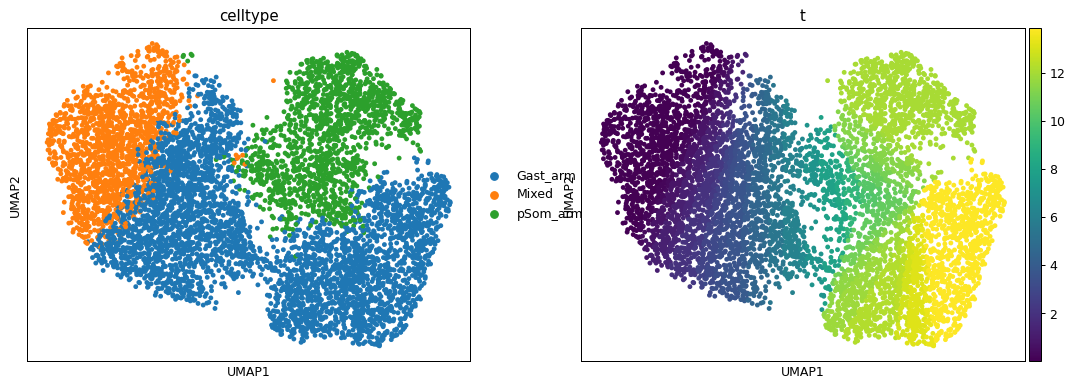

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
sc.pl.umap(adata, color=['celltype','t'], size=60); plt.show()

### Gast XOR pSom genes; select hub (Mixed) cells

In [4]:
get_feat = lambda p: set(pd.read_csv(p).hsapiens.dropna())
gast = get_feat(os.path.join(FEAT, 'GSE162534.csv'))
psom = get_feat(os.path.join(FEAT, 'GSE229103.csv'))
g = pd.Series(list(gast ^ psom)); g = g[g.isin(adata.var_names)]
print('Gast XOR pSom genes in data:', g.size)
adata_corr = adata[adata.obs.celltype == 'Mixed', g].copy()
print('Mixed hub cells:', adata_corr.n_obs)

Gast XOR pSom genes in data: 114
Mixed hub cells: 1513


### Pseudotime-windowed module mutual correlation, smoothed over neighbors

In [5]:
n_cells = 80; t = adata_corr.obs.t
n_bins = max(3, t.size // n_cells)
# quantile bins keep each window populated; guard against windows with <2 cells
t_bin = pd.qcut(t, q=n_bins, duplicates='drop')
adata_corr.obs['t_bin'] = t_bin
grp = adata_corr.obs.groupby('t_bin', observed=True)
r_dict = {}
for b, sdf in grp:
    if sdf.shape[0] < 3:
        continue
    ab = adata_corr[sdf.index].copy()
    X = pd.DataFrame(ab.X.toarray(), index=sdf.index, columns=g)
    X = X.loc[:, X.nunique(axis=0) > 1]
    if X.shape[1] < 2:
        continue
    a = pearsonr(X, sdf.GSE162534.values[:, None], axis=0).statistic
    b2 = pearsonr(X, sdf.GSE229103.values[:, None], axis=0).statistic
    r_dict[b] = np.corrcoef(a, b2)[0, 1]
A = adata_corr.obsp['connectivities']
R = t_bin.map(r_dict).astype(float)
R_sm = (A @ R.fillna(R.mean())) / A.sum(axis=1).A1
adata_corr.obs['correlation'] = R_sm
print('n windows used:', len(r_dict), '| windowed r range: %.3f to %.3f' % (min(r_dict.values()), max(r_dict.values())))
print('mean windowed r across hub = %.3f' % np.mean(list(r_dict.values())))
print('smoothed correlation range: %.3f to %.3f' % (np.nanmin(R_sm), np.nanmax(R_sm)))

n windows used: 18 | windowed r range: -0.580 to 0.303
mean windowed r across hub = -0.164
smoothed correlation range: -0.539 to 0.239


### `correlation.pdf` (+ R colorbar)
Module correlation is negative across the hub — Gast and pSom modules are mutually anti-correlated where they converge (cross-repression).

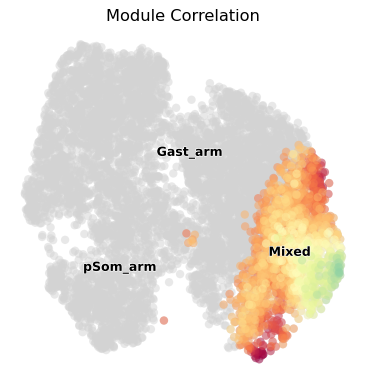

In [6]:
vlim = .5
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax)
sc.pl.umap(adata_corr, color='correlation', cmap='Spectral', vmin=-vlim, vmax=vlim,
           size=180, alpha=.5, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Module Correlation', size=13)
fig.savefig(os.path.join(pth_fig, 'correlation.pdf'), bbox_inches='tight'); plt.show()

saved correlation.pdf + colorbars/R_colorbar.pdf


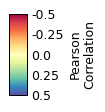

In [7]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Pearson\nCorrelation'); cb.ax.invert_yaxis()
ticks = np.asarray([-.5,-.25,0,.25,.5]); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved correlation.pdf + colorbars/R_colorbar.pdf')